In [1]:
from pathlib import Path
ROOT_DIR = Path(".")
DATASET_DIR = ROOT_DIR / "dataset/Poles2025"

import numpy as np
np.random.seed(42)

from IPython.display import Image, display
from PIL import Image as PILImage
from io import BytesIO

### Road_poles_iPhone

Sample images

In [ ]:
from anomaly_detection import sample_and_display_from_splits

TARGET_DATASET = "Road_poles_iPhone"
SPLIT_TO_IMAGES_DIR = {
    "train": "images/Train/train",
    "valid": "images/Validation/val",
    "test": "images/Test/test",
}

SUBSET_DIR = DATASET_DIR / TARGET_DATASET

sample_and_display_from_splits(
    subset_dir=SUBSET_DIR,
    split_to_images_dir=SPLIT_TO_IMAGES_DIR,
    sample_per_split=8,
    rotate_270=False,
    seed=42,
)

Detecting anomalous images

In [ ]:
from anomaly_detection import run_anomaly_workflow

workflow = run_anomaly_workflow(
    subset_dir=SUBSET_DIR,
    split_to_images_dir=SPLIT_TO_IMAGES_DIR,
    train_split="train",
    n_estimators=1000,
    contamination=0.02,
    random_state=42,
    n_jobs=-1,
)

df = workflow["df"]
df.sort_values("anomaly_score", ascending=True).head(10)

In [ ]:
for split, X in workflow["embeddings_by_split"].items():
    print(f"{split}: {X.shape}")

In [ ]:
from anomaly_detection import show_top_for_each_split

show_top_for_each_split(
    df,
    split_order=list(SPLIT_TO_IMAGES_DIR.keys()),
    k=12,
    cols=4,
)

### roadpoles_v1

Sample images

In [ ]:
from anomaly_detection import sample_and_display_from_splits

TARGET_DATASET = "roadpoles_v1"
SPLIT_TO_IMAGES_DIR = {
    "train": "train/images",
    "valid": "valid/images",
    "test": "test/images",
}

SUBSET_DIR = DATASET_DIR / TARGET_DATASET

sample_and_display_from_splits(
    subset_dir=SUBSET_DIR,
    split_to_images_dir=SPLIT_TO_IMAGES_DIR,
    sample_per_split=8,
    rotate_270=False,
    seed=42,
)

Detecting anomalous images

In [ ]:
from anomaly_detection import run_anomaly_workflow

workflow = run_anomaly_workflow(
    subset_dir=SUBSET_DIR,
    split_to_images_dir=SPLIT_TO_IMAGES_DIR,
    train_split="train",
    n_estimators=1000,
    contamination=0.02,
    random_state=42,
    n_jobs=-1,
)

df = workflow["df"]
df.sort_values("anomaly_score", ascending=True).head(10)

In [ ]:
for split, X in workflow["embeddings_by_split"].items():
    print(f"{split}: {X.shape}")

In [ ]:
from anomaly_detection import show_top_for_each_split

show_top_for_each_split(
    df,
    split_order=list(SPLIT_TO_IMAGES_DIR.keys()),
    k=12,
    cols=4,
)

### RoadPoles-MSJ

Merged subdirectories inside RoadPoles-MSJ

Merged images copied: 952
Merged test directory: dataset/Poles2025/RoadPoles-MSJ-merged/test
SPLIT: test | total images: 952 | sampling size: 13
Displaying: ['dataset/Poles2025/RoadPoles-MSJ-merged/test/20250319_083536_2205714428.jpg', 'dataset/Poles2025/RoadPoles-MSJ-merged/test/20250319_083810_2205867884.jpg', 'dataset/Poles2025/RoadPoles-MSJ-merged/test/20250319_143033_2227018866.jpg', 'dataset/Poles2025/RoadPoles-MSJ-merged/test/20250319_143033_2227042735.jpg', 'dataset/Poles2025/RoadPoles-MSJ-merged/test/20250319_083810_2205930690.jpg', 'dataset/Poles2025/RoadPoles-MSJ-merged/test/20250319_143033_2226977529.jpg', 'dataset/Poles2025/RoadPoles-MSJ-merged/test/20250319_143033_2227116375.jpg', 'dataset/Poles2025/RoadPoles-MSJ-merged/test/20250319_083810_2205942557.jpg', 'dataset/Poles2025/RoadPoles-MSJ-merged/test/20250319_150050_2228750479.jpg', 'dataset/Poles2025/RoadPoles-MSJ-merged/test/20250319_083536_2205698960.jpg', 'dataset/Poles2025/RoadPoles-MSJ-merged/test/20250319_083536_2



In [2]:
from pathlib import Path
import shutil

from anomaly_detection import sample_and_display_from_splits

SOURCE_SUBSET_DIR = DATASET_DIR / "RoadPoles-MSJ"
MERGED_SUBSET_DIR = DATASET_DIR / "RoadPoles-MSJ-merged"
MERGED_TEST_DIR = MERGED_SUBSET_DIR / "test"

MERGED_TEST_DIR.mkdir(parents=True, exist_ok=True)

copied = 0
for subdir in sorted(SOURCE_SUBSET_DIR.glob("*")):
    if not subdir.is_dir():
        continue
    for img_path in sorted(subdir.glob("*.jpg")):
        target_name = f"{subdir.name}_{img_path.name}"
        target_path = MERGED_TEST_DIR / target_name
        if not target_path.exists():
            shutil.copy2(img_path, target_path)
            copied += 1

print(f"Merged images copied: {copied}")
print(f"Merged test directory: {MERGED_TEST_DIR}")

TARGET_DATASET = "RoadPoles-MSJ-merged"
SPLIT_TO_IMAGES_DIR = {
    "test": "test",
}

SUBSET_DIR = DATASET_DIR / TARGET_DATASET

sample_and_display_from_splits(
    subset_dir=SUBSET_DIR,
    split_to_images_dir=SPLIT_TO_IMAGES_DIR,
    sample_per_split=13,
    rotate_270=True,
    seed=42,
)

Detecting anomalous images (merged test split)

In [6]:
from anomaly_detection import run_anomaly_workflow

workflow = run_anomaly_workflow(
    subset_dir=SUBSET_DIR,
    split_to_images_dir=SPLIT_TO_IMAGES_DIR,
    train_split="test",
    n_estimators=1000,
    contamination=0.01,
    random_state=42,
    n_jobs=-1,
 )

df = workflow["df"]
df.sort_values("anomaly_score", ascending=True).head(10)

test=952
device: cuda


  0%|          | 0/15 [00:00<?, ?it/s]

test: (952, 2048)


,split,path,anomaly_score
946,test,dataset/Poles2025/RoadPoles-MSJ-merged/test/20...,-0.053452
22,test,dataset/Poles2025/RoadPoles-MSJ-merged/test/20...,-0.029583
214,test,dataset/Poles2025/RoadPoles-MSJ-merged/test/20...,-0.026370
947,test,dataset/Poles2025/RoadPoles-MSJ-merged/test/20...,-0.022826
945,test,dataset/Poles2025/RoadPoles-MSJ-merged/test/20...,-0.015189
840,test,dataset/Poles2025/RoadPoles-MSJ-merged/test/20...,-0.004270
567,test,dataset/Poles2025/RoadPoles-MSJ-merged/test/20...,-0.004019
950,test,dataset/Poles2025/RoadPoles-MSJ-merged/test/20...,-0.003968
215,test,dataset/Poles2025/RoadPoles-MSJ-merged/test/20...,-0.000264
191,test,dataset/Poles2025/RoadPoles-MSJ-merged/test/20...,-0.000210


In [7]:
for split, X in workflow["embeddings_by_split"].items():
    print(f"{split}: {X.shape}")

test: (952, 2048)


Top 12 anomalies for split='test'


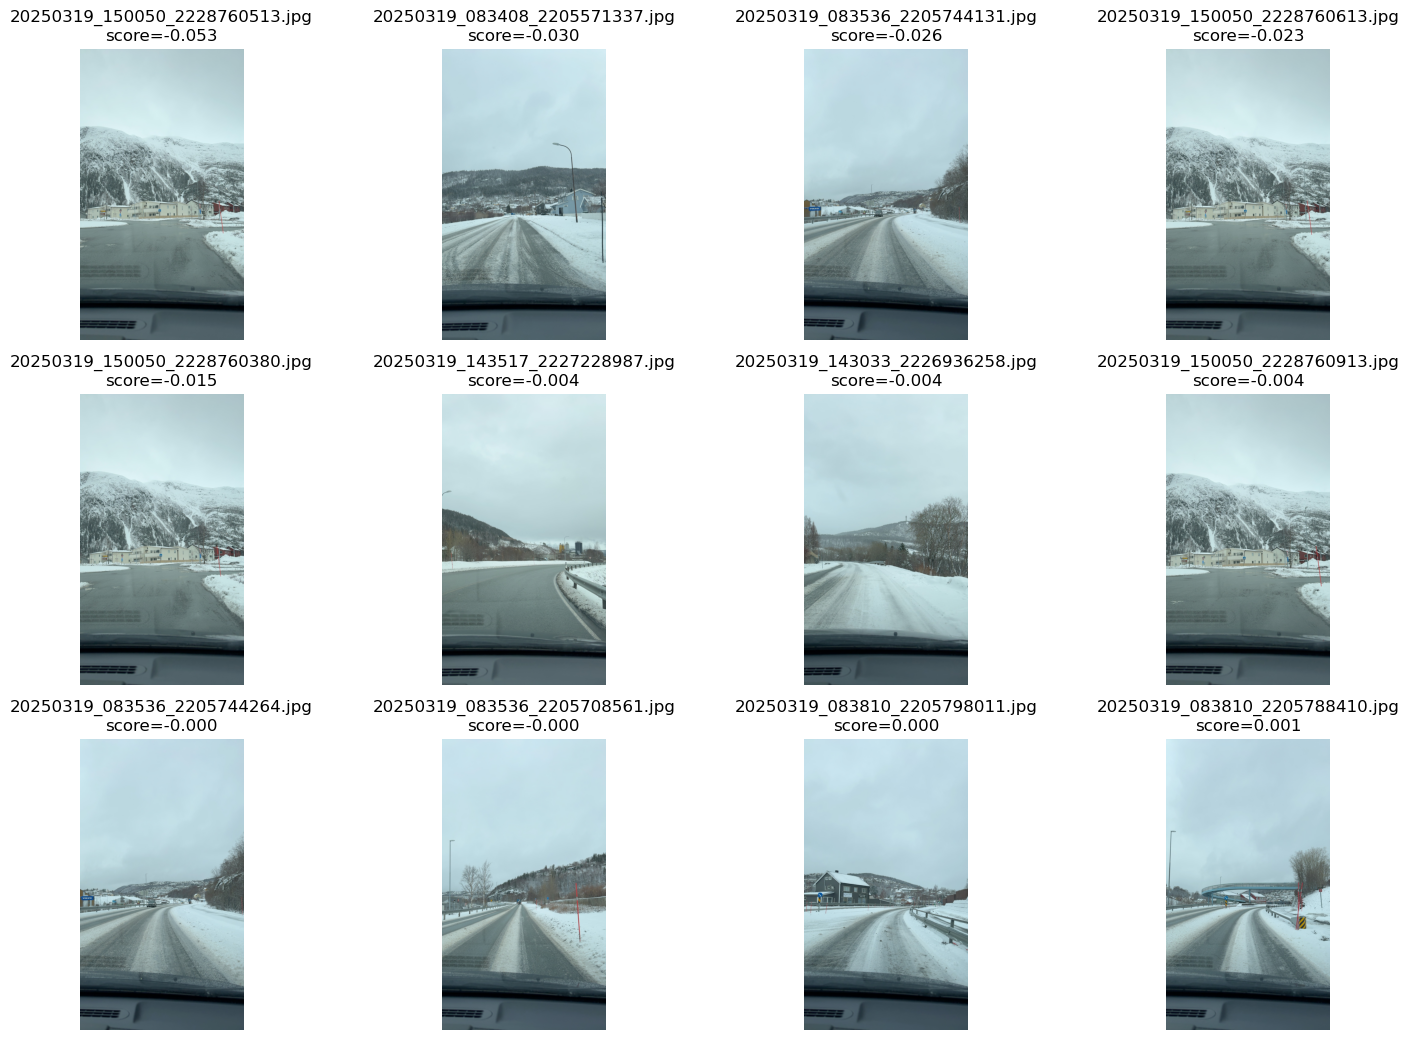

In [8]:
from anomaly_detection import show_top_for_each_split

show_top_for_each_split(
    df,
    split_order=["test"],
    k=12,
    cols=4,
    rotate_270=True
)